# Exploratory analysis: Brussels (A) and Antwerp (B)

*Benelux region, EUR.  City C (Amsterdam) is deliberately **not** loaded in this notebook: it is the unseen
new-client city and was only touched after the pipeline and the model for A and B were frozen (git tag `week1-final`).*

## Summary

**What we know**

* **Grain**: one row = one Airbnb listing as of the scrape (`id` is unique; one `scrape_id` per city).
  Brussels has **4,850** listings (snapshot 2026-09-20), Antwerp **2,463** (snapshot 2026-09-23); both were scraped 25-26 Sept 2026.
* **Target**: `price` = the nightly price Airbnb quoted for one specific stay (check-in date and number of nights in
  `price_quote_*`), stored as text like `"$1,234.00"`, though the currency is EUR. Median is **€125** (Brussels) and **€130.5** (Antwerp).
  Prices are strongly right-skewed (log-normal-ish), so we model `log(price)`.
* **Price is missing for 15.5 % (Brussels) and 20.1 % (Antwerp), and the gaps are not random.** 89 % / 98 % of listings with
  `availability_365 = 0` have no price, against 4 % / 9 % of the others. Listings with no availability got no price quote.
  We **drop** these rows from training. We do **not** impute them: they are mostly inactive listings, and an imputed price would be invented.
* **Review scores are missing exactly when `number_of_reviews = 0`** (100 % / 0 %): the gaps are structural, not errors.
* **15 columns are 100 % empty in this snapshot** (`host_since`, `bathrooms`, `license`, `instant_bookable`,
  `host_response_rate`, ...). Inside Airbnb's schema changes between snapshots, so the pipeline needs an explicit column contract.
* **Two pricing regimes**: listings with `minimum_nights >= 28` are quoted with Airbnb's monthly discount. Their nightly price is about half
  (median €63 vs €130 in Brussels). `is_long_stay` is a feature, not an outlier rule.
* **Leakage**: `price_quote_price_per_night` (= price), `price_quote_total_price` (= price x nights), `price_quote_raw`
  (JSON containing the price) and `estimated_revenue_l365d` (= price x estimated occupancy, exact for 100 % of rows) are computed
  from the target and are never used as features.
* **Outliers**: 0 prices below €15 and 30 above €1,000. They are mostly 0-review listings with placeholder prices (a 1-guest private
  room at €1,500+) or whole-house event rentals. They are flagged, not deleted, and are excluded from training and the primary MAE.

**What we still do not know**

* The quote is for one particular date. Seasonality and weekday-vs-weekend pricing are invisible in a single snapshot, and the
  check-in date varies by listing (from tomorrow up to almost a year out).
* Cleaning fees and service fees are not in `price`, so the price a guest actually pays is unknown.
* Whether a missing price means "inactive" or "fully booked": `availability_365 = 0` cannot tell them apart.
* How well relationships learned in two Belgian cities carry over to a city with a different price level and neighbourhood
  structure. That is exactly what the city-C exercise measures.

In [1]:
import os, json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Pinned snapshots => the notebook is reproducible even after Inside Airbnb publishes newer data.
SNAPSHOTS = {
    "brussels": ("2026-09-20", "https://data.insideairbnb.com/belgium/bru/brussels/2026-09-20/data/listings.csv.gz"),
    "antwerp":  ("2026-09-23", "https://data.insideairbnb.com/belgium/vlg/antwerp/2026-09-23/data/listings.csv.gz"),
}
# Same layout as the pipeline's raw volume; works locally (data/raw) and on Databricks (/Volumes/...)
RAW = "/Volumes/workspace/airbnb_benelux/raw" if os.path.isdir("/Volumes/workspace/airbnb_benelux/raw") else os.path.join("..", "data", "raw")

def load(city):
    date, url = SNAPSHOTS[city]
    path = os.path.join(RAW, city, date, "listings.csv.gz")
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as r, open(path, "wb") as f:
            f.write(r.read())
    return pd.read_csv(path, low_memory=False).assign(city=city, snapshot_date=date)

raw = pd.concat([load(c) for c in SNAPSHOTS], ignore_index=True)
raw["price_num"] = pd.to_numeric(raw["price"].str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
CITIES = list(SNAPSHOTS)

## 1. The dataset: snapshot dates, grain, record counts

In [2]:
desc = raw.groupby("city").agg(
    snapshot_date=("snapshot_date", "first"),
    rows=("id", "size"), unique_ids=("id", "nunique"), scrape_ids=("scrape_id", "nunique"),
    first_scraped=("last_scraped", "min"), last_scraped=("last_scraped", "max"),
    hosts=("host_id", "nunique"), neighbourhoods=("neighbourhood_cleansed", "nunique"),
    priced_rows=("price_num", "count"))
desc["columns"] = raw.drop(columns=["city", "snapshot_date", "price_num"]).shape[1]
desc

,snapshot_date,rows,unique_ids,scrape_ids,first_scraped,last_scraped,hosts,neighbourhoods,priced_rows,columns
city,,,,,,,,,,
antwerp,2026-09-23,2463,2463,1,2026-09-25,2026-09-26,1270,54,1967,90
brussels,2026-09-20,4850,4850,1,2026-09-25,2026-09-25,2949,19,4096,90


`rows == unique_ids` and each city has a single `scrape_id`, so **one row is one listing at one scrape**. There are no duplicates.
The pipeline still de-duplicates on `id` (keeping the latest `last_scraped`), because future snapshots are not guaranteed to be clean.

## 2. Column profile: types and missing values

In [3]:
USED = ["id","price","room_type","property_type","accommodates","bedrooms","beds","bathrooms","bathrooms_text",
        "amenities","minimum_nights","number_of_reviews","number_of_reviews_ltm","reviews_per_month",
        "review_scores_rating","review_scores_cleanliness","review_scores_location","review_scores_value",
        "host_is_superhost","calculated_host_listings_count","hosts_time_as_host_years",
        "latitude","longitude","neighbourhood_cleansed","availability_365"]
prof = pd.DataFrame({
    "raw dtype": raw[USED].dtypes.astype(str),
    "example": raw[USED].iloc[0].astype(str).str.slice(0, 40),
    **{f"missing % {c}": (raw.loc[raw.city == c, USED].isna().mean() * 100).round(1) for c in CITIES},
})
prof

,raw dtype,example,missing % brussels,missing % antwerp
id,int64,45026,0.0,0.0
price,object,$83.00,15.5,20.1
room_type,object,Entire home/apt,0.0,0.0
property_type,object,Entire rental unit,0.0,0.0
accommodates,int64,1,0.0,0.0
bedrooms,float64,1.0,0.0,0.1
beds,float64,1.0,3.5,1.9
bathrooms,float64,nan,100.0,100.0
bathrooms_text,object,1 bath,0.1,0.1
amenities,object,"[""Dedicated workspace"", ""Shampoo"", ""Extr",0.0,0.0


In [4]:
empty = raw.groupby("city").apply(lambda d: d.columns[d.isna().all()].tolist(), include_groups=False)
print("Columns that are 100% empty in this snapshot:")
for c, cols in empty.items():
    print(f"  {c} ({len(cols)}):", ", ".join(cols))

Columns that are 100% empty in this snapshot:
  antwerp (15): neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, bathrooms, calendar_updated, license, instant_bookable
  brussels (15): neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, bathrooms, calendar_updated, license, instant_bookable


**Typing**: `price` is text (`"$83.00"`) and needs parsing. Booleans are `'t'/'f'`. `amenities` is a JSON array in a string.
`bathrooms` is empty, so the count has to be parsed from `bathrooms_text` (`"1.5 shared baths"`, `"Half-bath"`).
That parse also gives a *shared bathroom* flag. The 100 %-empty columns are dropped from use. The pipeline creates them as NULL when a
snapshot lacks them, rather than crashing.

### Missing-value *patterns*

In [5]:
r = raw.assign(price_missing=raw["price_num"].isna(),
               no_availability=raw["availability_365"].eq(0),
               no_reviews=raw["number_of_reviews"].eq(0),
               rating_missing=raw["review_scores_rating"].isna())
pat = pd.concat({
  "P(price missing | availability_365 = 0)": r[r.no_availability].groupby("city").price_missing.mean(),
  "P(price missing | availability_365 > 0)": r[~r.no_availability].groupby("city").price_missing.mean(),
  "P(price missing | 0 reviews in last 12m)": r[r.number_of_reviews_ltm.eq(0)].groupby("city").price_missing.mean(),
  "P(price missing | >=1 review in last 12m)": r[r.number_of_reviews_ltm.gt(0)].groupby("city").price_missing.mean(),
  "P(rating missing | 0 reviews)": r[r.no_reviews].groupby("city").rating_missing.mean(),
  "P(rating missing | >=1 review)": r[~r.no_reviews].groupby("city").rating_missing.mean(),
}, axis=1).T.round(3)
pat

city,antwerp,brussels
P(price missing | availability_365 = 0),0.977,0.890
P(price missing | availability_365 > 0),0.093,0.044
P(price missing | 0 reviews in last 12m),0.429,0.300
P(price missing | >=1 review in last 12m),0.112,0.110
P(rating missing | 0 reviews),1.000,1.000
P(rating missing | >=1 review),0.000,0.000


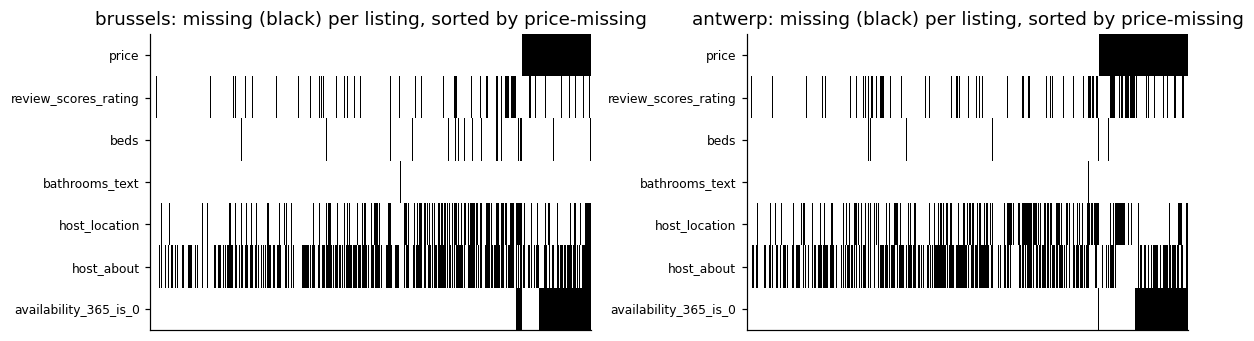

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, c in zip(ax, CITIES):
    d = r[r.city == c]
    m = d[["price","review_scores_rating","beds","bathrooms_text","host_location","host_about"]].isna()
    m = m.assign(availability_365_is_0=d["no_availability"]).astype(int)
    a.imshow(m.sort_values(["price","availability_365_is_0"]).T.values, aspect="auto", cmap="Greys", interpolation="nearest")
    a.set_yticks(range(m.shape[1])); a.set_yticklabels(m.columns, fontsize=8); a.set_xticks([])
    a.set_title(f"{c}: missing (black) per listing, sorted by price-missing")
plt.tight_layout(); plt.show()

* **Price**: missing *not at random*. It is missing for nearly every listing with no availability in the next 365 days, and is much more
  often missing for listings with no recent reviews. Those are inactive listings, with no bookable night to quote.
  Rule: rows with no price are kept in silver (they count as supply on the dashboard) but are **excluded from training and evaluation**.
  The model still produces a *suggested* price for them.
* **Review scores**: missing if and only if the listing has no reviews. This is structural. Tree models handle NaN natively, and linear
  candidates get median imputation plus a missing indicator.
* **Beds** (2-4 %) and **bathrooms_text** (0.1 %): small and random-looking, so they are imputed inside the model pipeline.
* **Host text fields**: optional free text, not used.

## 3. Distributions: price and availability

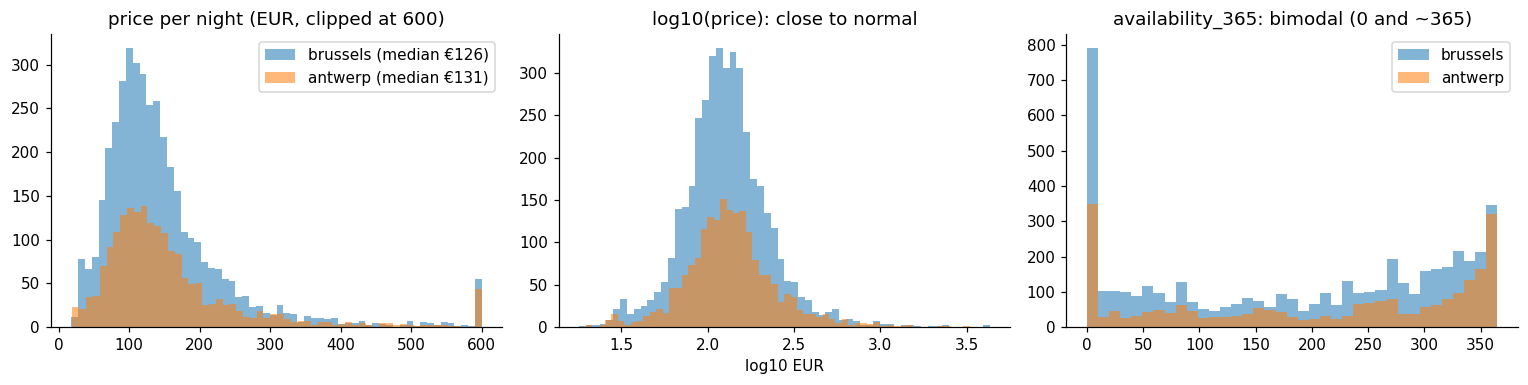

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
city,,,,,,,,,,,,,
antwerp,1967.0,168.2,167.8,19.7,29.0,53.6,96.0,131.0,181.2,393.8,824.9,2325.6,3300.0
brussels,4096.0,156.1,160.9,18.0,31.2,53.4,93.0,125.5,173.0,325.6,654.9,2220.3,4300.0


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for c in CITIES:
    p = raw.loc[raw.city == c, "price_num"].dropna()
    ax[0].hist(p.clip(upper=600), bins=60, alpha=.55, label=f"{c} (median €{p.median():.0f})")
    ax[1].hist(np.log10(p), bins=60, alpha=.55, label=c)
    ax[2].hist(raw.loc[raw.city == c, "availability_365"], bins=37, alpha=.55, label=c)
ax[0].set_title("price per night (EUR, clipped at 600)"); ax[0].legend()
ax[1].set_title("log10(price): close to normal"); ax[1].set_xlabel("log10 EUR")
ax[2].set_title("availability_365: bimodal (0 and ~365)"); ax[2].legend()
plt.tight_layout(); plt.show()
raw.groupby("city")["price_num"].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99,.999]).round(1)

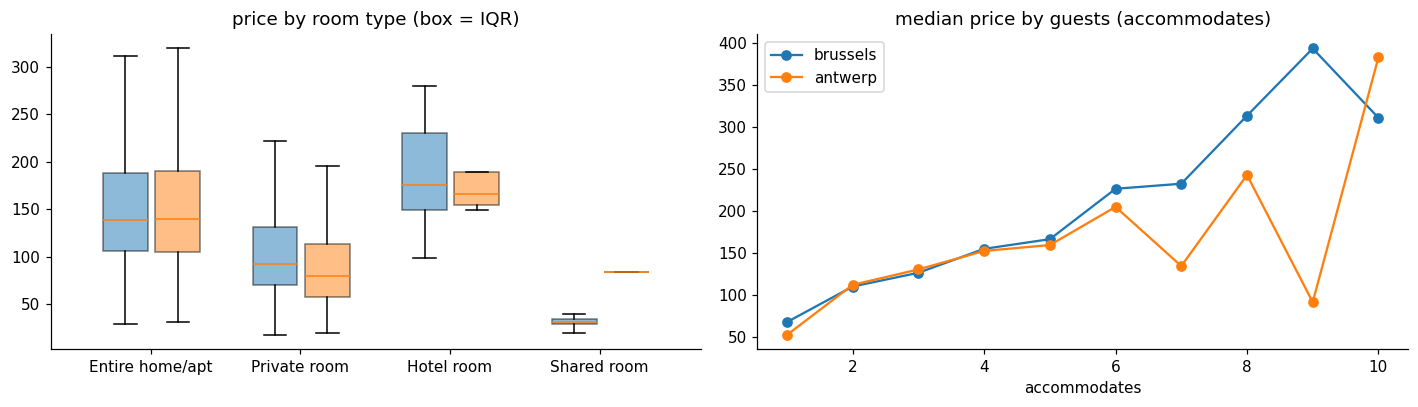

room_type,Entire home/apt,Hotel room,Private room,Shared room
city,,,,
antwerp,0.837,0.004,0.159,0.000
brussels,0.724,0.005,0.266,0.006


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
order = ["Entire home/apt", "Private room", "Hotel room", "Shared room"]
for i, c in enumerate(CITIES):
    d = raw[(raw.city == c) & raw.price_num.notna()]
    ax[0].boxplot([d.loc[d.room_type == rt, "price_num"] for rt in order], positions=np.arange(4) + i * .35,
                  widths=.3, showfliers=False, patch_artist=True, boxprops=dict(alpha=.5, facecolor=f"C{i}"))
    g = d[d.accommodates <= 10].groupby("accommodates")["price_num"].median()
    ax[1].plot(g.index, g.values, marker="o", label=c)
ax[0].set_xticks(np.arange(4) + .17); ax[0].set_xticklabels(order); ax[0].set_title("price by room type (box = IQR)")
ax[1].set_title("median price by guests (accommodates)"); ax[1].set_xlabel("accommodates"); ax[1].legend()
plt.tight_layout(); plt.show()
pd.crosstab(raw.city, raw.room_type, normalize="index").round(3)

In [9]:
r["long_stay"] = r["minimum_nights"] >= 28
r.groupby(["city", "long_stay"]).agg(listings=("id", "size"), median_price=("price_num", "median")).round(1)

listings  median_price
city     long_stay                        
antwerp  False          2297         135.0
         True            166          52.6
brussels False          4454         130.0
         True            396          63.3

* Price is right-skewed with a long tail (99th percentile €655 / €825, max €4,300). On a log scale it is roughly normal, so the model
  is trained on `log(price)` and predictions are exponentiated back. This also makes errors roughly proportional to price.
* `availability_365` is bimodal: a block at 0 (inactive or fully blocked calendars, 12-13 %) and a block near 365 (always open).
  Brussels listings are slightly less available (mean 186 vs 206 days).
* **Room type** and **guests** drive price, and these two variables define the baseline. Antwerp has more entire homes (84 % vs 72 %).
* **Long-stay listings** (min. 28 nights, 7-8 %) advertise roughly **half** the nightly price, because the quote includes the monthly discount
  (visible in `price_quote_raw.is_monthly_priced`). This is a different pricing regime, so it is encoded as a feature.

## 4. Outliers and how we classify them

In [10]:
def price_status(p):
    return np.select([p.isna(), p < 15, p > 1000], ["missing", "low_outlier (<15)", "high_outlier (>1000)"], "ok")
r["price_status"] = price_status(r["price_num"])
display(pd.crosstab(r.city, r.price_status, margins=True))
r.loc[r.price_status.str.startswith("high"),
      ["city","price_num","room_type","property_type","accommodates","bedrooms","number_of_reviews","minimum_nights","availability_365"]
     ].sort_values("price_num", ascending=False).head(15)

price_status,high_outlier (>1000),missing,ok,All
city,,,,
antwerp,10,496,1957,2463
brussels,20,754,4076,4850
All,30,1250,6033,7313


,city,price_num,room_type,property_type,accommodates,bedrooms,number_of_reviews,minimum_nights,availability_365
1502,brussels,4300.00,Entire home/apt,Entire villa,16,9.0,0,1.0,335
229,brussels,3994.25,Private room,Private room in home,2,1.0,25,4.0,365
5536,antwerp,3300.00,Entire home/apt,Entire home,14,7.0,1,1.0,135
6791,antwerp,2400.00,Entire home/apt,Entire home,14,7.0,0,1.0,127
5814,antwerp,2323.00,Private room,Private room in home,1,1.0,0,1.0,209
90,brussels,2283.00,Entire home/apt,Entire rental unit,4,2.0,0,1.0,270
3229,brussels,2283.00,Entire home/apt,Entire rental unit,2,1.0,0,1.0,365
1821,brussels,2241.15,Private room,Private room in home,1,1.0,0,365.0,365
4421,brussels,2022.00,Entire home/apt,Entire home,12,6.0,3,1.0,359
4304,brussels,1626.67,Private room,Private room in home,9,8.0,2,1.0,165


In [11]:
odd = pd.DataFrame({
  "bedrooms > 15": r.groupby("city").bedrooms.apply(lambda s: (s > 15).sum()),
  "beds > 30": r.groupby("city").beds.apply(lambda s: (s > 30).sum()),
  "accommodates = 16 (Airbnb cap)": r.groupby("city").accommodates.apply(lambda s: (s == 16).sum()),
  "minimum_nights > 365": r.groupby("city").minimum_nights.apply(lambda s: (s > 365).sum()),
  "price per guest > 300": r.assign(ppg=r.price_num / r.accommodates).groupby("city").ppg.apply(lambda s: (s > 300).sum()),
})
odd

,bedrooms > 15,beds > 30,accommodates = 16 (Airbnb cap),minimum_nights > 365,price per guest > 300
city,,,,,
antwerp,1,3,14,1,7
brussels,0,1,23,3,11


| class | rule | what it is | treatment |
|---|---|---|---|
| missing price | `price` NULL | inactive listing with no quotable night (see section 2) | keep in silver, exclude from training/evaluation, still scored |
| high outlier | price > €1,000 (0.5 % of priced) | mostly 0-1-review listings with placeholder prices (1-guest private room at €1,500+), plus a few genuine villas | flag `price_status='high_outlier'`; excluded from training and primary MAE; reported separately |
| low outlier | price < €15 | none in A/B; kept as a guard for future snapshots | same as above |
| implausible attribute | bedrooms > 15 (one Antwerp listing has 25 bedrooms for 2 guests), beds > 30 | data-entry error | value set to NULL, row kept |
| capped value | accommodates = 16 | Airbnb's maximum, so it really means "16+" | kept |
| long minimum stay | minimum_nights >= 28 | a different price regime, not an error | feature `is_long_stay`; `minimum_nights` capped at 365 |

We chose a fixed, explainable rule (€15 / €1,000) over a percentile rule: a percentile cut would shift with each city's price level,
and in a new city it would silently delete genuine expensive listings.

## 5. Cleaning and transformations the pipeline must apply

| # | step | layer | reason |
|---|---|---|---|
| 1 | read CSV with `multiLine=true, escape='"'` | bronze | descriptions contain newlines and quotes; a naive reader splits rows |
| 2 | keep every column as string, add `city`, `snapshot_date`, `source_file`, `ingested_at` | bronze | bronze is a faithful copy; lineage for every row |
| 3 | explicit column contract: required columns -> fail, optional missing -> NULL + warning | silver | the schema changes between snapshots (15 columns empty now) |
| 4 | `try_cast` every column | silver | Databricks serverless runs ANSI SQL; one bad value would otherwise fail the job |
| 5 | parse `price` (`"$1,234.00"` -> 1234.0), `'t'/'f'` -> boolean, `%` -> fraction, dates | silver | typed analytics |
| 6 | `amenities` JSON -> `array<string>`, `amenities_count`, flags for 9 amenities | silver/gold | features |
| 7 | `bathrooms` <- number in `bathrooms_text` (half-bath = 0.5), `bathroom_shared` flag | silver | the `bathrooms` column is empty |
| 8 | `property_base` = property_type without "Entire / Private room in / Room in" | silver | room_type already holds that part; avoids a 60-level category |
| 9 | de-duplicate on `id` (latest `last_scraped`); drop rows without id, coordinates, room_type or accommodates (counted in `dq_metrics`) | silver | grain guarantee; nothing silently disappears |
| 10 | `price_status` flag (missing / low / high / ok), `is_long_stay`, `is_active`, implausible bedrooms/beds -> NULL | silver | section 4 |
| 11 | drop `price_quote_*` columns | silver | computed from the target (leakage, section 6) |
| 12 | distance (km) to the city's listing-density centre (median lat/lon) | gold | a geography feature that means the same thing in every city, unlike raw coordinates |
| 13 | deterministic split `xxhash64(id, 42) mod 100 < 20` -> test | gold | the same 20 % test set in every run and for every consumer |

## 6. Leakage review

In [12]:
d = raw[raw.price_num.notna()].copy()
nights = (pd.to_datetime(d.price_quote_checkout_date) - pd.to_datetime(d.price_quote_checkin_date)).dt.days
checks = pd.DataFrame({
  "price_quote_price_per_night == price": np.isclose(d.price_quote_price_per_night, d.price_num),
  "price_quote_total_price == price x nights (2%)": np.isclose(d.price_quote_total_price, d.price_num * nights, rtol=.02),
  "price appears in price_quote_raw JSON": [f'"price_per_night": "' in str(j) for j in d.price_quote_raw],
  "estimated_revenue_l365d == price x estimated_occupancy_l365d (+-1)":
      (d.estimated_revenue_l365d - d.price_num * d.estimated_occupancy_l365d).abs() <= 1,
}).groupby(d.city).mean().T.round(4)
checks

city,antwerp,brussels
price_quote_price_per_night == price,1.0,0.9995
price_quote_total_price == price x nights (2%),1.0,0.9995
price appears in price_quote_raw JSON,1.0,0.9995
estimated_revenue_l365d == price x estimated_occupancy_l365d (+-1),1.0,1.0000


In [13]:
print("correlation with price (Spearman):")
cols = ["price_quote_price_per_night","price_quote_total_price","estimated_revenue_l365d","estimated_occupancy_l365d",
        "availability_30","availability_365","accommodates","bedrooms","review_scores_rating"]
raw[raw.price_num.notna()][cols + ["price_num"]].corr(method="spearman")["price_num"].drop("price_num").round(3).sort_values()

correlation with price (Spearman):


estimated_occupancy_l365d     -0.056
availability_365               0.036
review_scores_rating           0.142
availability_30                0.149
estimated_revenue_l365d        0.235
price_quote_total_price        0.296
bedrooms                       0.434
accommodates                   0.536
price_quote_price_per_night    1.000
Name: price_num, dtype: float64

| column(s) | verdict | why |
|---|---|---|
| `price_quote_price_per_night` | **leak, excluded** | identical to `price` (99.96 % / 100 %) |
| `price_quote_total_price` | **leak, excluded** | `price x nights` |
| `price_quote_raw` | **leak, excluded** | JSON containing the nightly price and line items |
| `estimated_revenue_l365d` | **leak, excluded** | Inside Airbnb computes it as `price x estimated_occupancy_l365d` (exact for 100 % of rows); kept in silver for the dashboard only |
| `price_quote_checkin_date`, `price_quote_checkout_date` | **excluded** | metadata of how the target was measured; present only when a quote exists, so their missingness encodes whether price is missing |
| `availability_30/60/90/365`, `has_availability`, `estimated_occupancy_l365d` | **excluded (not a formula leak)** | *consequences* of the price (expensive listings stay unbooked: reverse causality), and unknown when we suggest a price for a new listing; also strongly tied to whether the price is missing |
| `id`, `listing_url`, `scrape_id`, `host_id`, `name`, `picture_url` | excluded | identifiers; a model could memorise them, and they carry no meaning in another city |
| raw `latitude`/`longitude` | not used directly | legitimate, but coordinates do not transfer between cities; replaced by `dist_centre_km` |
| `neighbourhood_cleansed` | used via **target encoding fitted inside cross-validation** | encoding with the full data would leak each test listing's own price; sklearn's `TargetEncoder` cross-fits on the training split only |
| `number_of_reviews*`, `review_scores_*`, `reviews_per_month` | used | written by guests about the stay, not computed from price; they are a proxy for quality and popularity |
| `host_is_superhost`, `calculated_host_listings_count`, `hosts_time_as_host_years` | used | host professionalism, known independently of price |

**Feature set of the model** (all known before setting a price, none computed from it): room type, property group, guests, bedrooms, beds,
bathrooms, shared bathroom, amenity count plus 9 amenity flags, minimum nights, long-stay flag, review counts and scores, superhost,
host listing count, host years, distance to centre, city, and the target-encoded neighbourhood.

## 7. Baseline the model must beat

In [14]:
# Same rule as the pipeline: deterministic hash split. (pandas version of xxhash64 is not used here; this is only an illustration.)
ok = r[r.price_status == "ok"].copy()
rng = np.random.RandomState(42); ok["test"] = rng.rand(len(ok)) < .2
tr, te = ok[~ok.test], ok[ok.test]
med = tr.groupby(["room_type", "accommodates"]).price_num.median()
fallback = tr.groupby("room_type").price_num.median()
pred = [med.get((a, b), fallback.get(a, tr.price_num.median())) for a, b in zip(te.room_type, te.accommodates)]
te = te.assign(baseline=pred, abs_err=lambda x: (x.baseline - x.price_num).abs())
te.groupby("city").abs_err.mean().round(2).to_frame("baseline MAE (EUR, illustrative split)")

,"baseline MAE (EUR, illustrative split)"
city,
antwerp,59.62
brussels,49.89


On an illustrative random split, the median by (room type, guests) gets an MAE of roughly €50-60. The official baseline and model numbers come from the pipeline's
deterministic test split and are written to `gold_model_metrics` (see the README and `notebooks/04_train_model`).